In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_regression, f_classif

from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve)

In [2]:
reg_df = pd.read_csv('influencer_campaign_regression.csv')
print("Shape (rows, columns):", reg_df.shape)
reg_df.head()

Shape (rows, columns): (3000, 13)


,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd
0,425.4,2.14,1331,35.2,10,Static-Carousel,High-Intent-Niche,35,16,Android,Net-30,Sunny,15192.26
1,171.3,5.73,3925,25.4,10,YouTube-Deep-Dive,Lifestyle-Warm,26,16,Android,Upfront,Cloudy,20018.44
2,356.4,8.03,1817,9.4,0,Short-Video-Reel,High-Intent-Niche,43,24,Android,Upfront,Cloudy,21146.87
3,272.2,7.70,942,32.1,15,Short-Video-Reel,Lifestyle-Warm,113,9,Android,Net-15,Rainy,17639.62
4,143.0,6.06,3347,51.0,20,Short-Video-Reel,Broad-Entertainment,72,18,Android,Net-30,Cloudy,17375.60


In [3]:
# Data structure and data types
reg_df.head()
reg_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   creator_followers_k     3000 non-null   float64
 1   engagement_rate_pct     3000 non-null   float64
 2   paid_boost_spend_usd    3000 non-null   int64  
 3   avg_watch_time_sec      3000 non-null   float64
 4   promo_discount_pct      3000 non-null   int64  
 5   content_format          3000 non-null   str    
 6   audience_intent_tier    3000 non-null   str    
 7   caption_word_count      3000 non-null   int64  
 8   hashtags_used_count     3000 non-null   int64  
 9   creator_phone_os        3000 non-null   str    
 10  contract_payment_terms  3000 non-null   str    
 11  posting_day_weather     3000 non-null   str    
 12  campaign_revenue_usd    3000 non-null   float64
dtypes: float64(4), int64(4), str(5)
memory usage: 448.9 KB


In [4]:
# Descriptive statistics
print("Numeric columns:")
display(reg_df.describe().T)
print("Categorical columns:")
display(reg_df.describe(include="object").T)

Numeric columns:


,count,mean,std,min,25%,50%,75%,max
creator_followers_k,3000.0,232.592433,126.675186,15.00,122.4000,229.800,343.7250,449.90
engagement_rate_pct,3000.0,5.161417,2.539730,0.80,2.9275,5.180,7.4100,9.50
paid_boost_spend_usd,3000.0,2317.529667,1273.365953,100.00,1208.7500,2370.000,3416.2500,4499.00
avg_watch_time_sec,3000.0,30.266467,14.147323,6.10,17.9000,30.400,42.7000,55.00
promo_discount_pct,3000.0,12.358333,8.613245,0.00,5.0000,10.000,20.0000,25.00
caption_word_count,3000.0,86.810000,42.942674,12.00,50.0000,86.000,124.0000,159.00
hashtags_used_count,3000.0,12.367000,6.996473,1.00,6.0000,13.000,18.0000,24.00
campaign_revenue_usd,3000.0,16678.699140,4747.136562,2915.63,13222.8975,16480.745,19839.1575,32527.89


Categorical columns:


C:\Users\User\AppData\Local\Temp\ipykernel_18220\1556255673.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(reg_df.describe(include="object").T)


,count,unique,top,freq
content_format,3000,3,Short-Video-Reel,1518
audience_intent_tier,3000,3,Lifestyle-Warm,1215
creator_phone_os,3000,2,Android,1530
contract_payment_terms,3000,3,Net-15,1024
posting_day_weather,3000,3,Sunny,1025


In [5]:
# Missing values and duplicates
print("Missing values per column:")
print(reg_df.isnull().sum())
print()
print("Number of duplicate rows:", reg_df.duplicated().sum())

Missing values per column:
creator_followers_k       0
engagement_rate_pct       0
paid_boost_spend_usd      0
avg_watch_time_sec        0
promo_discount_pct        0
content_format            0
audience_intent_tier      0
caption_word_count        0
hashtags_used_count       0
creator_phone_os          0
contract_payment_terms    0
posting_day_weather       0
campaign_revenue_usd      0
dtype: int64

Number of duplicate rows: 0


In [6]:
# Outlier Anaylysis (IQR Method)
reg_num_cols = ["creator_followers_k", "engagement_rate_pct", "paid_boost_spend_usd",
                "avg_watch_time_sec", "promo_discount_pct", "caption_word_count",
                "hashtags_used_count", "campaign_revenue_usd"]

# Count outliers in each numeric column
rows = []
for col in reg_num_cols:
    q1 = reg_df[col].quantile(0.25)
    q3 = reg_df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((reg_df[col] < low) | (reg_df[col] > high)).sum()
    rows.append([col, round(low, 2), round(high, 2), n_out])
pd.DataFrame(rows, columns=["column", "lower_fence", "upper_fence", "n_outliers"])

,column,lower_fence,upper_fence,n_outliers
0,creator_followers_k,-209.59,675.71,0
1,engagement_rate_pct,-3.80,14.13,0
2,paid_boost_spend_usd,-2102.50,6727.50,0
3,avg_watch_time_sec,-19.30,79.90,0
4,promo_discount_pct,-17.50,42.50,0
5,caption_word_count,-61.00,235.00,0
6,hashtags_used_count,-12.00,36.00,0
7,campaign_revenue_usd,3298.51,29763.55,9


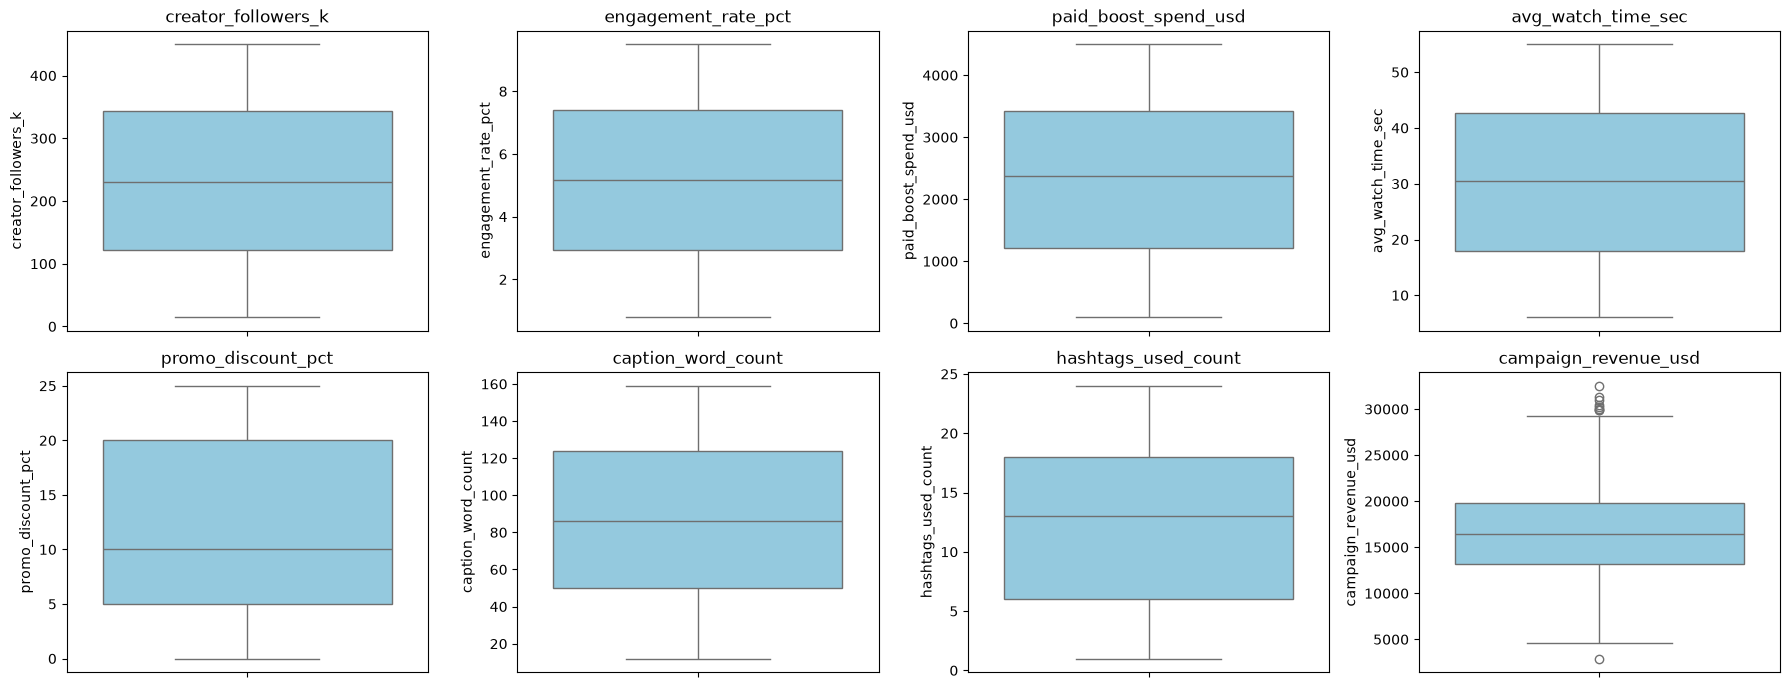

In [7]:
# Boxplots show outliers as dots
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), reg_num_cols):
    sns.boxplot(y=reg_df[col], ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

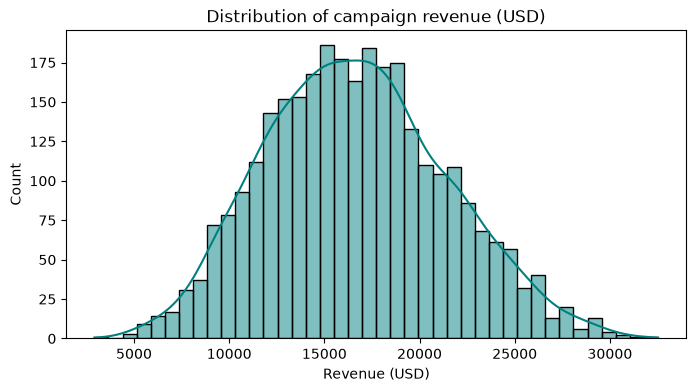

Skewness of target: 0.21 (close to 0 = fairly symmetric)


In [8]:
# Distribution of the target
plt.figure(figsize=(8, 4))
sns.histplot(reg_df["campaign_revenue_usd"], bins=40, kde=True, color="teal")
plt.title("Distribution of campaign revenue (USD)")
plt.xlabel("Revenue (USD)")
plt.show()
print("Skewness of target:", round(reg_df["campaign_revenue_usd"].skew(), 2), "(close to 0 = fairly symmetric)")

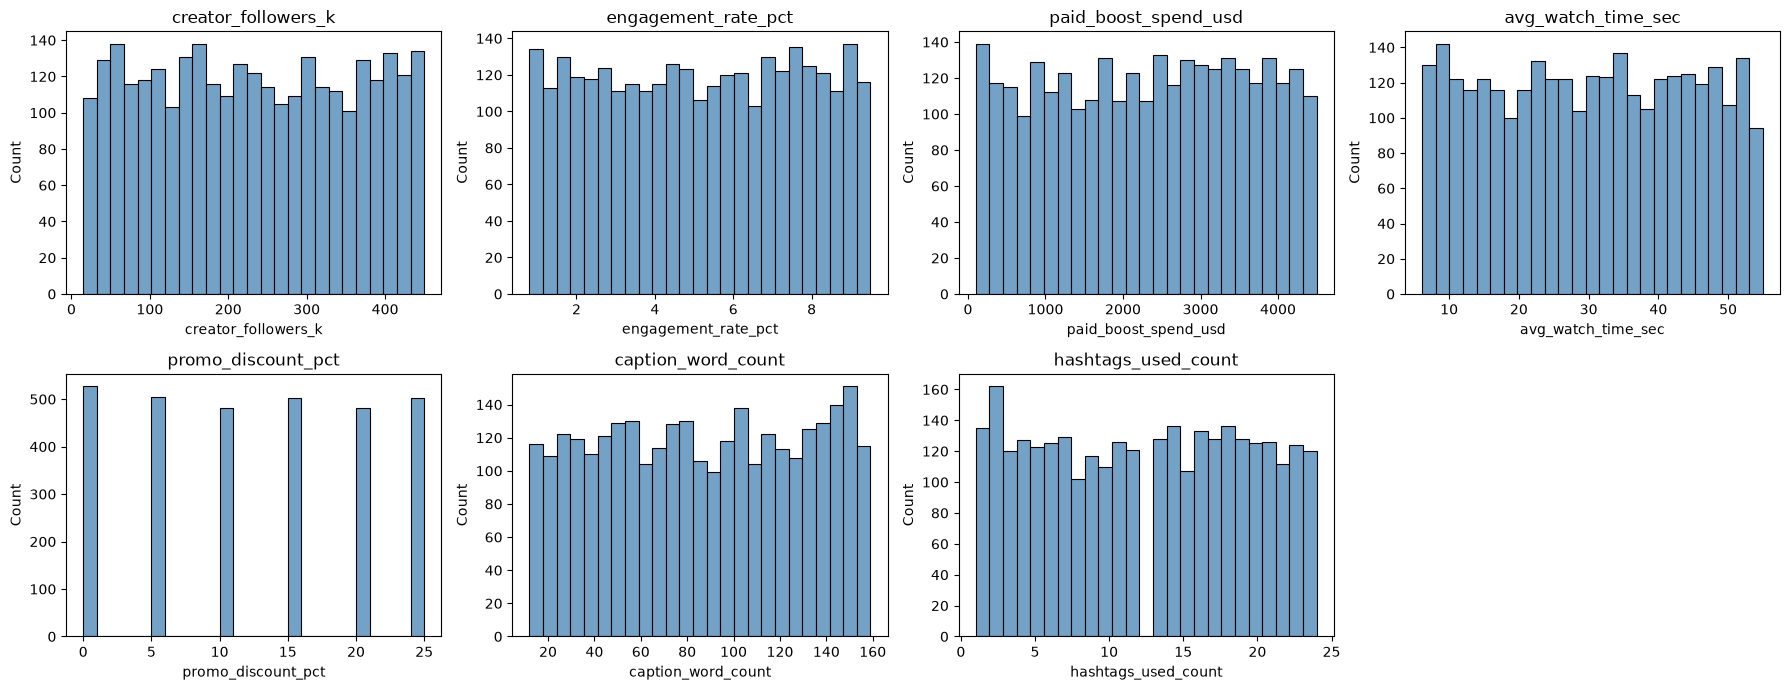

In [9]:
# Distribution of numeric features
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), reg_num_cols[:-1]):
    sns.histplot(reg_df[col], bins=25, ax=ax, color="steelblue")
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

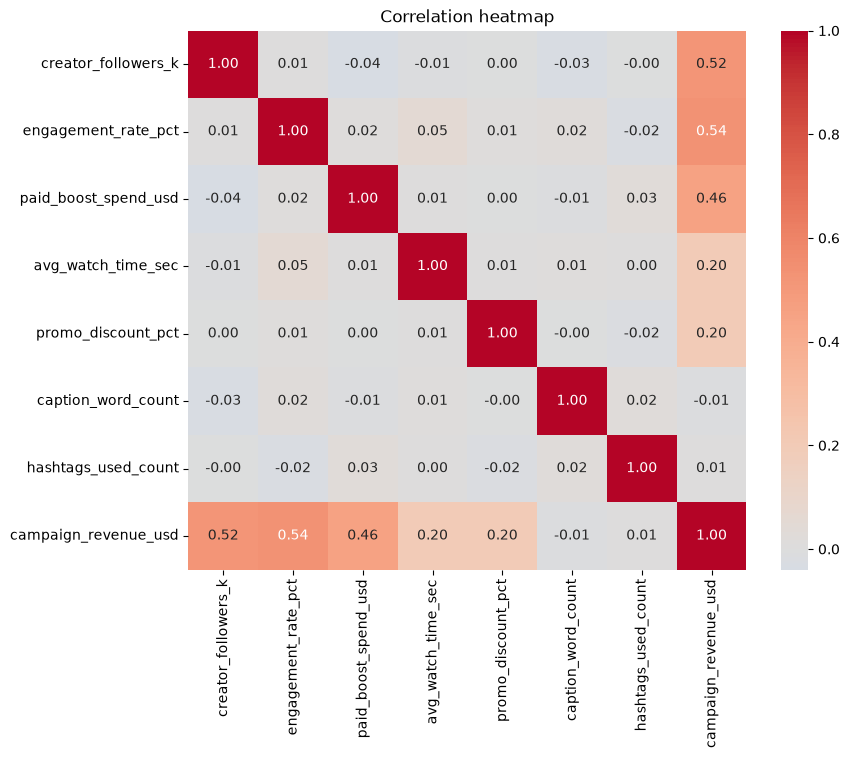

Correlation of each feature with the target:
engagement_rate_pct     0.536
creator_followers_k     0.519
paid_boost_spend_usd    0.456
promo_discount_pct      0.203
avg_watch_time_sec      0.198
hashtags_used_count     0.007
caption_word_count     -0.011
Name: campaign_revenue_usd, dtype: float64


In [10]:
# Correlation heatmap (numeric columns)
plt.figure(figsize=(9, 7))
sns.heatmap(reg_df[reg_num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

print("Correlation of each feature with the target:")
print(reg_df[reg_num_cols].corr()["campaign_revenue_usd"].drop("campaign_revenue_usd")
      .sort_values(ascending=False).round(3))

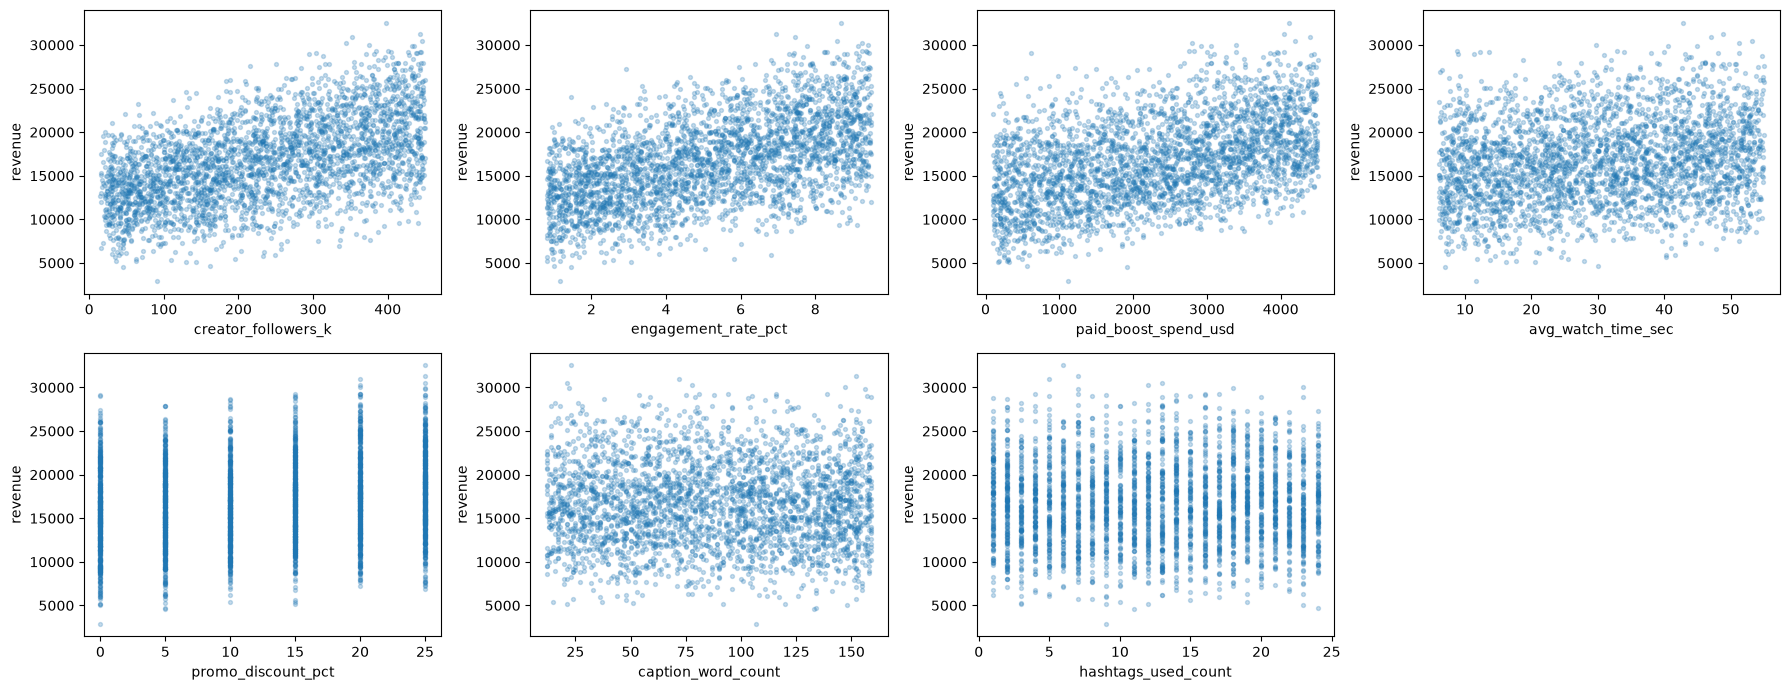

In [11]:
# Scatter plots: numeric features vs revenue
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), reg_num_cols[:-1]):
    ax.scatter(reg_df[col], reg_df["campaign_revenue_usd"], alpha=0.25, s=8)
    ax.set_xlabel(col)
    ax.set_ylabel("revenue")
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

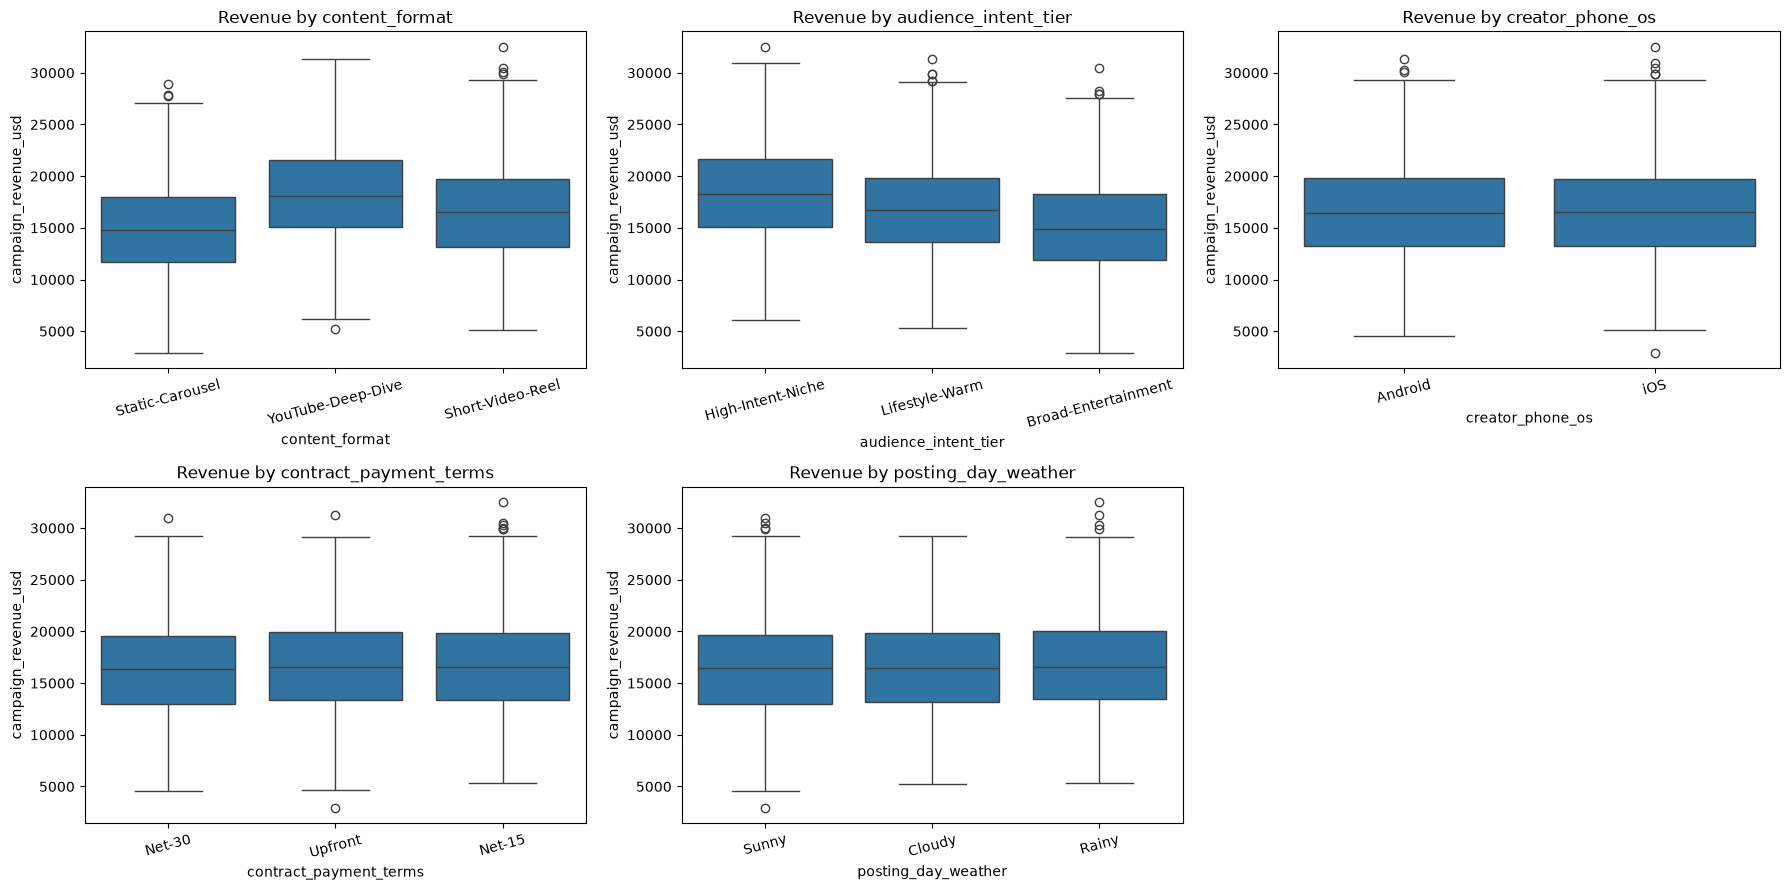

{'Short-Video-Reel': 16633.0, 'Static-Carousel': 15051.0, 'YouTube-Deep-Dive': 18369.0}
{'Broad-Entertainment': 15200.0, 'High-Intent-Niche': 18472.0, 'Lifestyle-Warm': 16828.0}
{'Android': 16640.0, 'iOS': 16719.0}
{'Net-15': 16755.0, 'Net-30': 16516.0, 'Upfront': 16765.0}
{'Cloudy': 16675.0, 'Rainy': 16852.0, 'Sunny': 16520.0}


In [12]:
# Categorical features vs revenue (boxplots)
reg_cat_cols = ["content_format", "audience_intent_tier", "creator_phone_os",
                "contract_payment_terms", "posting_day_weather"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flatten(), reg_cat_cols):
    sns.boxplot(x=reg_df[col], y=reg_df["campaign_revenue_usd"], ax=ax)
    ax.set_title("Revenue by " + col)
    ax.tick_params(axis="x", rotation=15)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

# Average revenue per category
for col in reg_cat_cols:
    print(reg_df.groupby(col)["campaign_revenue_usd"].mean().round(0).to_dict())

In [13]:
# Handle missing values and duplicates
reg_clean = reg_df.copy()

# Remove duplicate rows (there are none, but this keeps the pipeline safe)
reg_clean = reg_clean.drop_duplicates()

# Fill missing values: median for numbers, most common value for text
for col in reg_clean.columns:
    if reg_clean[col].isnull().sum() > 0:
        if not pd.api.types.is_numeric_dtype(reg_clean[col]):
            reg_clean[col] = reg_clean[col].fillna(reg_clean[col].mode()[0])
        else:
            reg_clean[col] = reg_clean[col].fillna(reg_clean[col].median())

print("Rows after cleaning:", len(reg_clean))
print("Missing values left:", reg_clean.isnull().sum().sum())

Rows after cleaning: 3000
Missing values left: 0


In [14]:
# Encode categorical variables (One-hot coding)
X_reg = reg_clean.drop(columns="campaign_revenue_usd")
y_reg = reg_clean["campaign_revenue_usd"]

X_reg = pd.get_dummies(X_reg, drop_first=True, dtype=int)
print("Number of features after encoding:", X_reg.shape[1])
X_reg.head()

Number of features after encoding: 16


,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,caption_word_count,hashtags_used_count,content_format_Static-Carousel,content_format_YouTube-Deep-Dive,audience_intent_tier_High-Intent-Niche,audience_intent_tier_Lifestyle-Warm,creator_phone_os_iOS,contract_payment_terms_Net-30,contract_payment_terms_Upfront,posting_day_weather_Rainy,posting_day_weather_Sunny
0,425.4,2.14,1331,35.2,10,35,16,1,0,1,0,0,1,0,0,1
1,171.3,5.73,3925,25.4,10,26,16,0,1,0,1,0,0,1,0,0
2,356.4,8.03,1817,9.4,0,43,24,0,0,1,0,0,0,1,0,0
3,272.2,7.70,942,32.1,15,113,9,0,0,0,1,0,0,0,1,0
4,143.0,6.06,3347,51.0,20,72,18,0,0,0,0,0,1,0,0,0


In [15]:
# Split into training (80%) and testing (20%) sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

print("Training rows:", X_train_reg.shape[0])
print("Testing rows: ", X_test_reg.shape[0])

Training rows: 2400
Testing rows:  600


In [16]:
# Only continuous columns are capped (not the 0/1 dummy columns)
reg_cap_cols = ["creator_followers_k", "engagement_rate_pct", "paid_boost_spend_usd",
                "avg_watch_time_sec", "promo_discount_pct", "caption_word_count",
                "hashtags_used_count"]

n_capped = 0
for col in reg_cap_cols:
    q1 = X_train_reg[col].quantile(0.25)
    q3 = X_train_reg[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_capped += ((X_train_reg[col] < low) | (X_train_reg[col] > high)).sum()
    X_train_reg[col] = X_train_reg[col].clip(low, high)   # cap training data
    X_test_reg[col] = X_test_reg[col].clip(low, high)     # apply SAME limits to test data

print("Number of feature values capped in training data:", n_capped)

Number of feature values capped in training data: 0


In [17]:
# Feature selection
f_values, p_values = f_regression(X_train_reg, y_train_reg)
reg_scores = pd.DataFrame({"feature": X_train_reg.columns, "F_score": f_values.round(1),
                           "p_value": p_values.round(4)}).sort_values("p_value")

# Link each dummy column back to its original column name
original_cols = [c for c in reg_df.columns if c != "campaign_revenue_usd"]
def original_name(dummy_name):
    for c in original_cols:
        if dummy_name == c or dummy_name.startswith(c + "_"):
            return c
reg_scores["original_column"] = reg_scores["feature"].apply(original_name)
reg_scores

,feature,F_score,p_value,original_column
0,creator_followers_k,893.9,0.0000,creator_followers_k
1,engagement_rate_pct,955.2,0.0000,engagement_rate_pct
2,paid_boost_spend_usd,597.9,0.0000,paid_boost_spend_usd
3,avg_watch_time_sec,96.7,0.0000,avg_watch_time_sec
4,promo_discount_pct,96.4,0.0000,promo_discount_pct
7,content_format_Static-Carousel,98.8,0.0000,content_format
9,audience_intent_tier_High-Intent-Niche,132.6,0.0000,audience_intent_tier
8,content_format_YouTube-Deep-Dive,111.0,0.0000,content_format
12,contract_payment_terms_Net-30,5.8,0.0157,contract_payment_terms
10,audience_intent_tier_Lifestyle-Warm,2.3,0.1262,audience_intent_tier


In [18]:
# Keep original columns that have at least one p-value < 0.01
keep_original = reg_scores[reg_scores["p_value"] < 0.01]["original_column"].unique()
drop_original = [c for c in original_cols if c not in keep_original]

selected_reg_features = [c for c in X_train_reg.columns if original_name(c) in keep_original]

print("KEPT columns:   ", list(keep_original))
print("DROPPED columns:", drop_original)

X_train_reg_sel = X_train_reg[selected_reg_features]
X_test_reg_sel = X_test_reg[selected_reg_features]

KEPT columns:    ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'avg_watch_time_sec', 'promo_discount_pct', 'content_format', 'audience_intent_tier']
DROPPED columns: ['caption_word_count', 'hashtags_used_count', 'creator_phone_os', 'contract_payment_terms', 'posting_day_weather']


In [19]:
# Double-check: does removing the noise columns hurt (or help) the model?
check_model = Pipeline([("scale", StandardScaler()), ("model", Ridge())])
score_all = cross_val_score(check_model, X_train_reg, y_train_reg, cv=5, scoring="r2").mean()
score_sel = cross_val_score(check_model, X_train_reg_sel, y_train_reg, cv=5, scoring="r2").mean()
print("CV R2 with ALL features:     ", round(score_all, 4))
print("CV R2 with SELECTED features:", round(score_sel, 4))

CV R2 with ALL features:      0.9728
CV R2 with SELECTED features: 0.9729


In [20]:
# Model Development
# Define the models (Ridge uses a scaler inside a pipeline)
reg_models = {
    "Baseline (Mean)":    DummyRegressor(strategy="mean"),
    "Ridge Regression":   Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
    "Random Forest":      RandomForestRegressor(random_state=42, n_jobs=-1),
    "Gradient Boosting":  GradientBoostingRegressor(random_state=42),
}

# 5-fold cross-validation on the training data
cv_rows = []
for name, model in reg_models.items():
    r2_scores = cross_val_score(model, X_train_reg_sel, y_train_reg, cv=5, scoring="r2")
    rmse_scores = -cross_val_score(model, X_train_reg_sel, y_train_reg, cv=5,
                                   scoring="neg_root_mean_squared_error")
    cv_rows.append([name, r2_scores.mean(), r2_scores.std(), rmse_scores.mean()])

reg_cv_table = pd.DataFrame(cv_rows, columns=["Model", "CV R2 (mean)", "CV R2 (std)", "CV RMSE (mean)"]).round(4)
reg_cv_table

,Model,CV R2 (mean),CV R2 (std),CV RMSE (mean)
0,Baseline (Mean),-0.0014,0.0011,4730.9270
1,Ridge Regression,0.9729,0.0021,777.6921
2,Random Forest,0.9025,0.0095,1474.0742
3,Gradient Boosting,0.9683,0.0022,840.8749


In [21]:
# Hyperparameter Tuning with GridSearchCV
reg_param_grids = {
    "Ridge Regression": {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {"n_estimators": [100, 200],
                      "max_depth": [None, 10],
                      "min_samples_leaf": [1, 5]},
    "Gradient Boosting": {"n_estimators": [100, 200],
                          "learning_rate": [0.05, 0.1],
                          "max_depth": [2, 3]},
}

reg_best_models = {}
reg_tuning_rows = []
for name, grid in reg_param_grids.items():
    search = GridSearchCV(reg_models[name], grid, cv=5,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
    start = time.time()
    search.fit(X_train_reg_sel, y_train_reg)
    seconds = time.time() - start

    reg_best_models[name] = search.best_estimator_
    reg_tuning_rows.append([name, search.best_params_, round(-search.best_score_, 2), round(seconds, 1)])

pd.DataFrame(reg_tuning_rows, columns=["Model", "Best parameters", "Best CV RMSE", "Tuning time (sec)"])

,Model,Best parameters,Best CV RMSE,Tuning time (sec)
0,Ridge Regression,{'model__alpha': 0.01},777.68,3.5
1,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",1470.35,9.9
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",695.14,7.4


In [22]:
# Model Evaluation
# The baseline has no tuning, so we fit it here
reg_baseline = reg_models["Baseline (Mean)"].fit(X_train_reg_sel, y_train_reg)
reg_final_models = {"Baseline (Mean)": reg_baseline}
reg_final_models.update(reg_best_models)

eval_rows = []
for name, model in reg_final_models.items():
    pred_test = model.predict(X_test_reg_sel)
    pred_train = model.predict(X_train_reg_sel)
    eval_rows.append([
        name,
        mean_absolute_error(y_test_reg, pred_test),
        np.sqrt(mean_squared_error(y_test_reg, pred_test)),
        r2_score(y_test_reg, pred_test),
        r2_score(y_train_reg, pred_train),
    ])

reg_results = pd.DataFrame(eval_rows, columns=["Model", "MAE", "RMSE", "R2 (test)", "R2 (train)"]).round(4)
reg_results

,Model,MAE,RMSE,R2 (test),R2 (train)
0,Baseline (Mean),3878.9846,4811.2663,-0.0004,0.0000
1,Ridge Regression,624.5015,797.5066,0.9725,0.9732
2,Random Forest,1069.1395,1334.7546,0.9230,0.9880
3,Gradient Boosting,528.6374,659.8675,0.9812,0.9910


In [23]:
# Model comparison and final model selection
comparison = reg_results[reg_results["Model"] != "Baseline (Mean)"].copy()
comparison["Overfit gap (R2 train - test)"] = (comparison["R2 (train)"] - comparison["R2 (test)"]).round(4)
comparison["Tuning time (sec)"] = [row[3] for row in reg_tuning_rows]
comparison["CV RMSE"] = [row[2] for row in reg_tuning_rows]
comparison["Interpretable?"] = ["Yes (coefficients)", "Partly (importances)", "Partly (importances)"]
comparison = comparison.set_index("Model")
display(comparison)

best_reg_name = comparison["RMSE"].idxmin()
print("Best model by test RMSE:", best_reg_name)

,MAE,RMSE,R2 (test),R2 (train),Overfit gap (R2 train - test),Tuning time (sec),CV RMSE,Interpretable?
Model,,,,,,,,
Ridge Regression,624.5015,797.5066,0.9725,0.9732,0.0007,3.5,777.68,Yes (coefficients)
Random Forest,1069.1395,1334.7546,0.9230,0.9880,0.0650,9.9,1470.35,Partly (importances)
Gradient Boosting,528.6374,659.8675,0.9812,0.9910,0.0098,7.4,695.14,Partly (importances)


Best model by test RMSE: Gradient Boosting


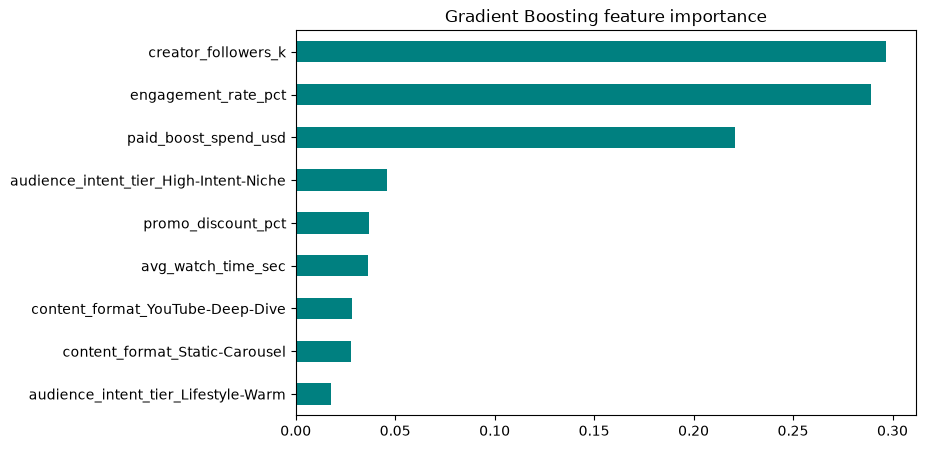

In [24]:
# What drives revenue in the final model?
best_reg_model = reg_best_models[best_reg_name]

if best_reg_name == "Ridge Regression":
    importance = pd.Series(best_reg_model.named_steps["model"].coef_, index=selected_reg_features)
    title = "Ridge coefficients (features are scaled, so sizes are comparable)"
else:
    importance = pd.Series(best_reg_model.feature_importances_, index=selected_reg_features)
    title = best_reg_name + " feature importance"

importance.sort_values().plot(kind="barh", figsize=(8, 5), color="teal")
plt.title(title)
plt.show()

In [25]:
# Data loading
clf_df = pd.read_csv('ecommerce_return_classification.csv')
print("Shape (rows, columns):", clf_df.shape)
clf_df.head()

Shape (rows, columns): (2993, 13)


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [26]:
# Dataset structure and data types
clf_df.head()
clf_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


In [27]:
# Descriptive Statistics
print("Numeric columns:")
display(clf_df.describe().T)
print("Categorical columns:")
display(clf_df.describe(include="object").T)

Numeric columns:


,count,mean,std,min,25%,50%,75%,max
cart_value_usd,2993.0,239.750301,121.394772,25.010,135.560,238.740,343.920,449.860
past_return_rate,2993.0,0.284024,0.159998,0.005,0.157,0.265,0.386,0.884
size_bracketing_flag,2993.0,0.354160,0.478338,0.000,0.000,0.000,1.000,1.000
delivery_days_taken,2993.0,5.974273,3.188330,1.000,3.000,6.000,9.000,11.000
discount_pct_applied,2993.0,23.879051,17.263143,0.000,10.000,20.000,40.000,50.000
newsletter_subscriber,2993.0,0.503508,0.500071,0.000,0.000,1.000,1.000,1.000
return_risk_label,2993.0,0.645506,0.478440,0.000,0.000,1.000,1.000,1.000


Categorical columns:


C:\Users\User\AppData\Local\Temp\ipykernel_18220\2581958579.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(clf_df.describe(include="object").T)


,count,unique,top,freq
product_category,2993,4,Casual-Tops,1015
fit_review_sentiment,2993,3,True-to-Size,1498
browser_used,2993,4,Firefox,752
checkout_device,2993,3,Android-App,1036
packaging_color,2993,3,Kraft-Brown,1010
loyalty_card_color,2993,3,Platinum,1023


In [28]:
#Missing values, duplicates and class balance
print("Missing values per column:")
print(clf_df.isnull().sum())
print()
print("Number of duplicate rows:", clf_df.duplicated().sum())
print()
print("Target class counts:")
print(clf_df["return_risk_label"].value_counts())
print()
print("Target class percentages:")
print((clf_df["return_risk_label"].value_counts(normalize=True) * 100).round(1))

Missing values per column:
cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

Number of duplicate rows: 0

Target class counts:
return_risk_label
1    1932
0    1061
Name: count, dtype: int64

Target class percentages:
return_risk_label
1    64.6
0    35.4
Name: proportion, dtype: float64


C:\Users\User\AppData\Local\Temp\ipykernel_18220\367189586.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="return_risk_label", data=clf_df, palette="Set2")


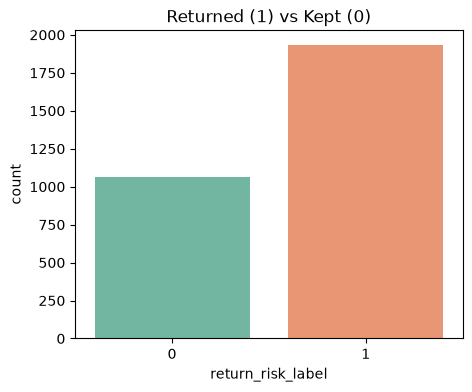

In [29]:
plt.figure(figsize=(5, 4))
sns.countplot(x="return_risk_label", data=clf_df, palette="Set2")
plt.title("Returned (1) vs Kept (0)")
plt.show()

In [30]:
# Outlier analysis (IQR method)
clf_num_cols = ["cart_value_usd", "past_return_rate", "delivery_days_taken", "discount_pct_applied"]

rows = []
for col in clf_num_cols:
    q1 = clf_df[col].quantile(0.25)
    q3 = clf_df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((clf_df[col] < low) | (clf_df[col] > high)).sum()
    rows.append([col, round(low, 3), round(high, 3), n_out])
pd.DataFrame(rows, columns=["column", "lower_fence", "upper_fence", "n_outliers"])

,column,lower_fence,upper_fence,n_outliers
0,cart_value_usd,-176.980,656.46,0
1,past_return_rate,-0.187,0.73,25
2,delivery_days_taken,-6.000,18.00,0
3,discount_pct_applied,-35.000,85.00,0


c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\User\Documents\ML Portfol

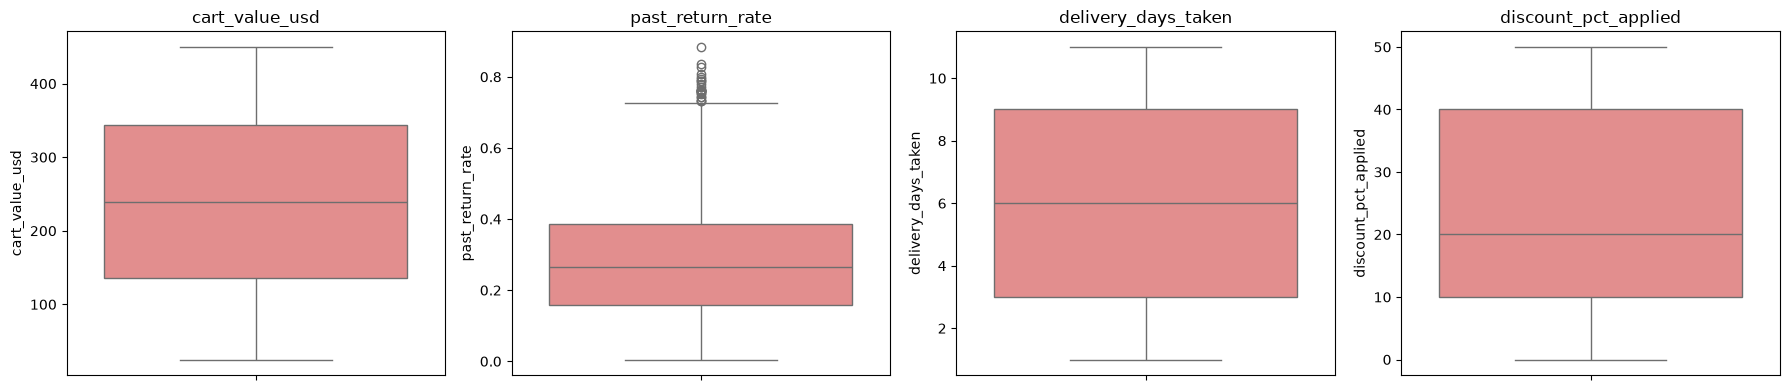

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, clf_num_cols):
    sns.boxplot(y=clf_df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.tight_layout()
plt.show()

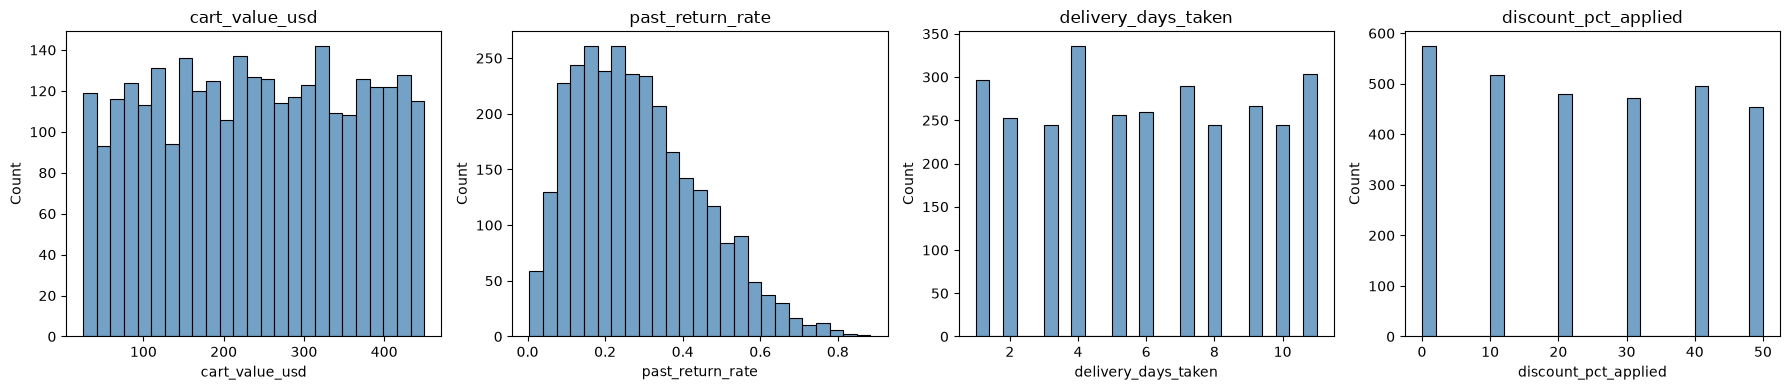

In [32]:
# Distribution of numeric features
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, clf_num_cols):
    sns.histplot(clf_df[col], bins=25, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\User\Documents\ML Portfol

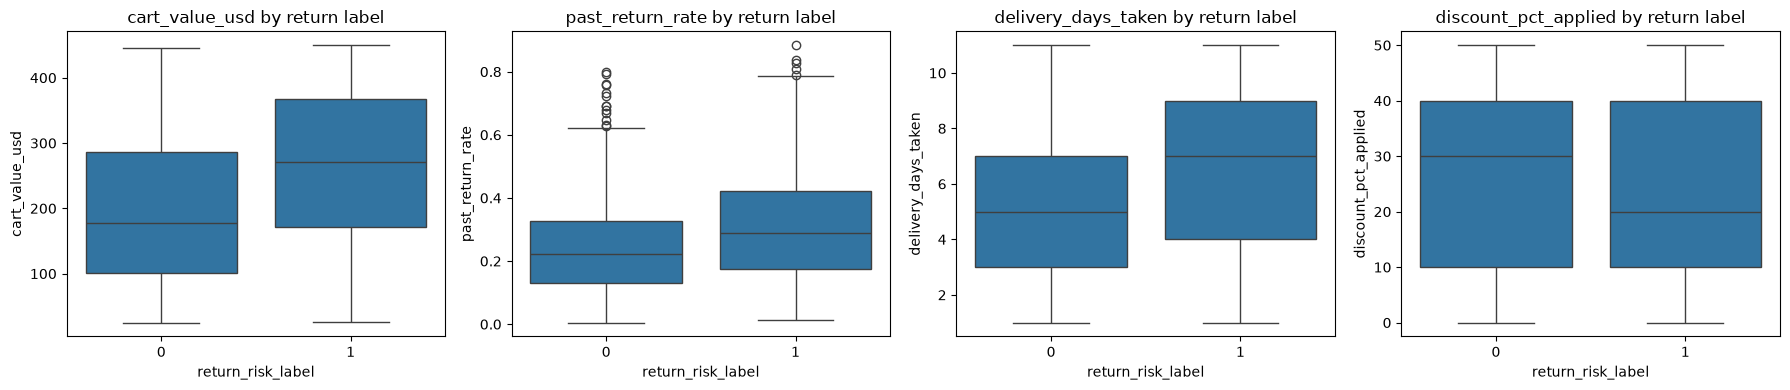

In [33]:
# Numeric features split by target (returned vs kept)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, clf_num_cols):
    sns.boxplot(x="return_risk_label", y=col, data=clf_df, ax=ax)
    ax.set_title( col +" by return label")
plt.tight_layout()
plt.show()

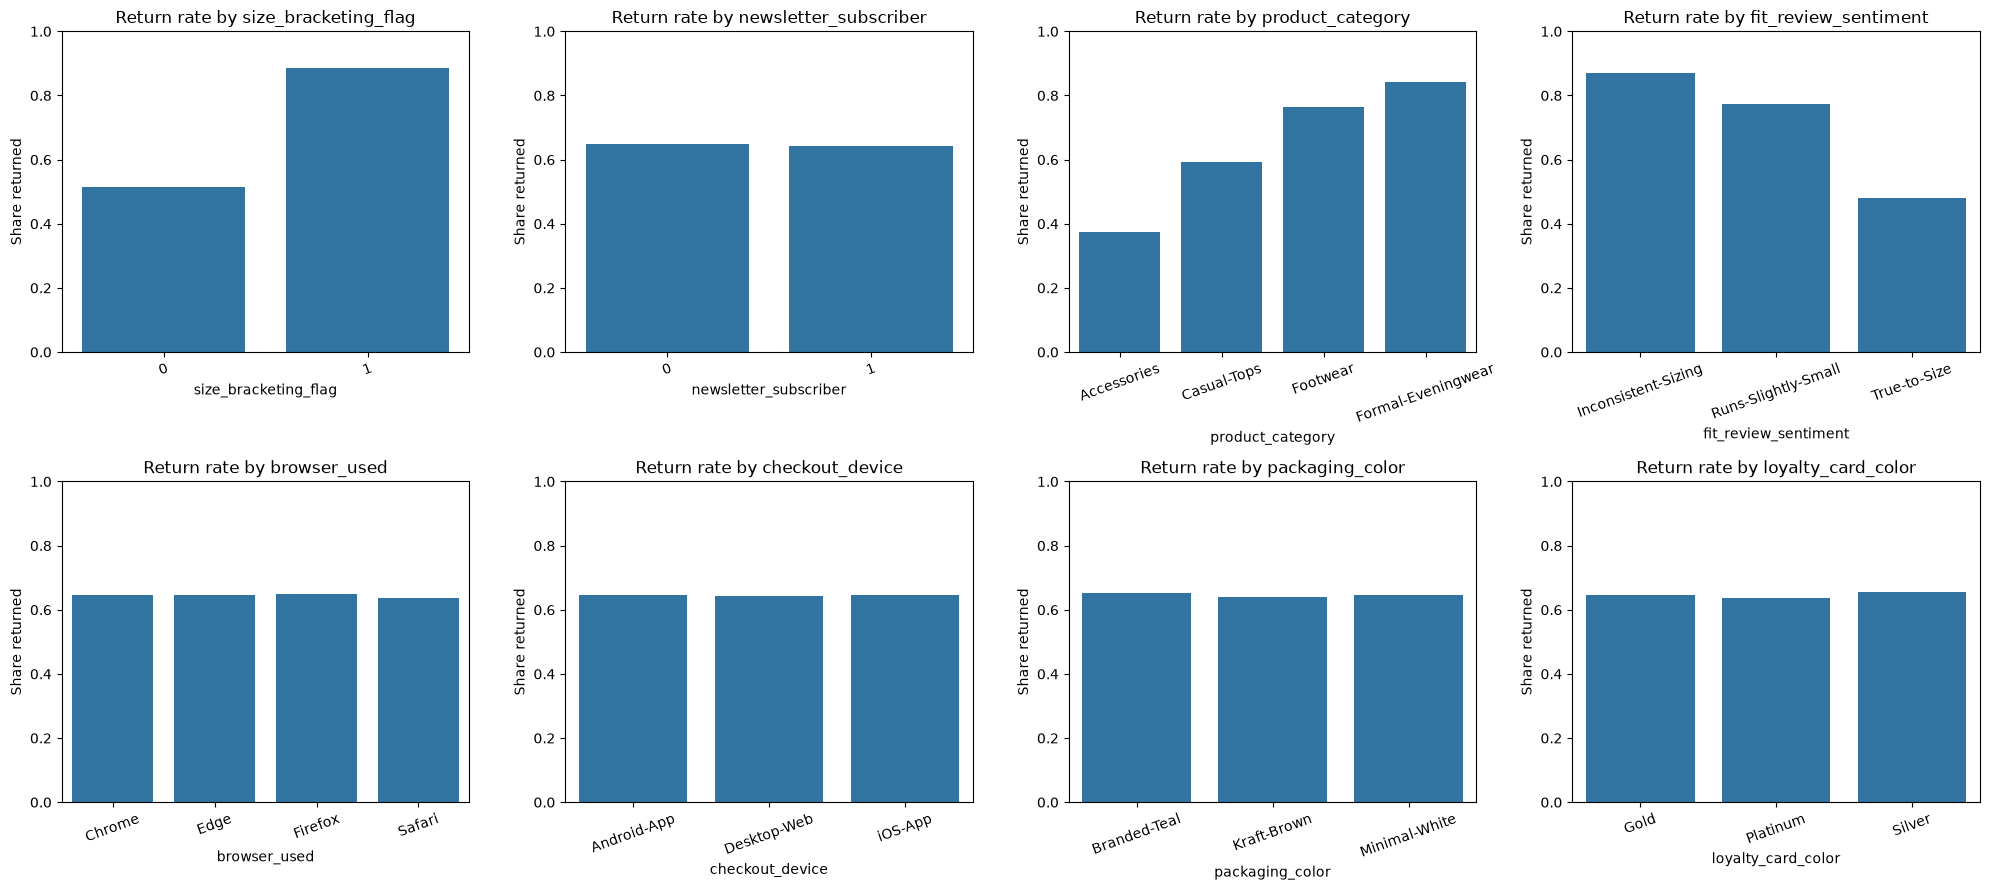

In [34]:
# Return rate for each binary / categorical feature
clf_cat_cols = ["size_bracketing_flag", "newsletter_subscriber", "product_category",
                "fit_review_sentiment", "browser_used", "checkout_device",
                "packaging_color", "loyalty_card_color"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flatten(), clf_cat_cols):
    rate = clf_df.groupby(col)["return_risk_label"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title("Return rate by " + col)
    ax.set_ylabel("Share returned")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

c:\Users\User\Documents\ML Portfolio\Machine-learning-Portfolio-Project\ML-Portfolio\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


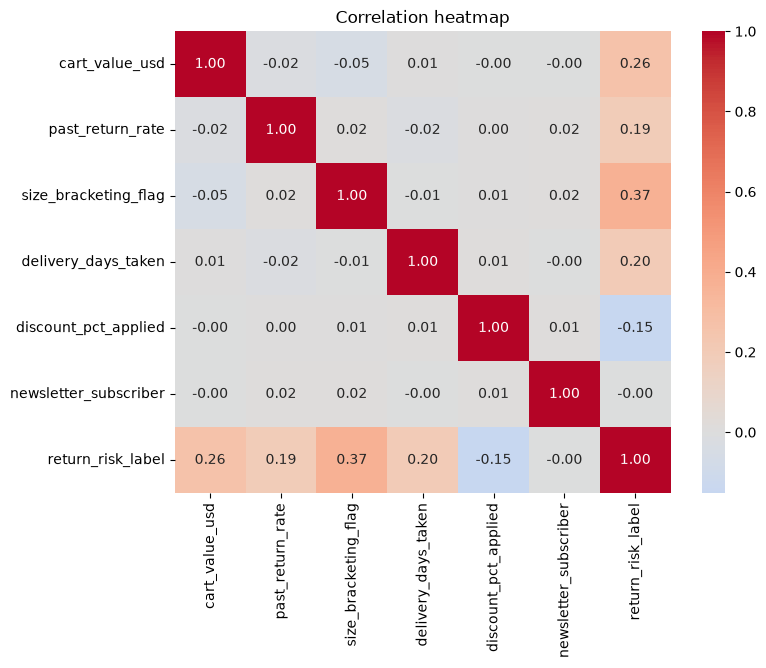

In [35]:
# Correlation heatmap for numeric columns
clf_corr_cols = ["cart_value_usd", "past_return_rate", "size_bracketing_flag",
                 "delivery_days_taken", "discount_pct_applied",
                 "newsletter_subscriber", "return_risk_label"]
plt.figure(figsize=(8, 6))
sns.heatmap(clf_df[clf_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

In [36]:
# Handle missing values and duplicates
clf_clean = clf_df.copy()

clf_clean = clf_clean.drop_duplicates()

for col in clf_clean.columns:
    if clf_clean[col].isnull().sum() > 0:
        if not pd.api.types.is_numeric_dtype(clf_clean[col]):
            clf_clean[col] = clf_clean[col].fillna(clf_clean[col].mode()[0])
        else:
            clf_clean[col] = clf_clean[col].fillna(clf_clean[col].median())

print("Rows after cleaning:", len(clf_clean))
print("Missing values left:", clf_clean.isnull().sum().sum())

Rows after cleaning: 2993
Missing values left: 0


In [37]:
# Encode categorical variables (One-Hot Encoding)
X_clf = clf_clean.drop(columns="return_risk_label")
y_clf = clf_clean["return_risk_label"]

X_clf = pd.get_dummies(X_clf, drop_first=True, dtype=int)
print("Number of features after encoding:", X_clf.shape[1])
X_clf.head()

Number of features after encoding: 20


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,newsletter_subscriber,product_category_Casual-Tops,product_category_Footwear,product_category_Formal-Eveningwear,fit_review_sentiment_Runs-Slightly-Small,fit_review_sentiment_True-to-Size,browser_used_Edge,browser_used_Firefox,browser_used_Safari,checkout_device_Desktop-Web,checkout_device_iOS-App,packaging_color_Kraft-Brown,packaging_color_Minimal-White,loyalty_card_color_Platinum,loyalty_card_color_Silver
0,172.17,0.233,1,11,10,1,0,1,0,0,1,0,0,1,0,0,1,0,1,0
1,213.55,0.235,1,6,40,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1
2,371.70,0.461,1,11,40,0,0,0,1,0,1,0,1,0,0,1,1,0,0,0
3,317.18,0.080,0,1,20,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0
4,152.68,0.133,0,3,40,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1


In [38]:
#Split into training (80%) and testing (20%) sets
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print("Training rows:", X_train_clf.shape[0])
print("Testing rows: ", X_test_clf.shape[0])
print("Share returned in train:", round(y_train_clf.mean(), 3))
print("Share returned in test: ", round(y_test_clf.mean(), 3))

Training rows: 2394
Testing rows:  599
Share returned in train: 0.645
Share returned in test:  0.646


In [39]:
clf_cap_cols = ["cart_value_usd", "past_return_rate", "delivery_days_taken", "discount_pct_applied"]

n_capped = 0
for col in clf_cap_cols:
    q1 = X_train_clf[col].quantile(0.25)
    q3 = X_train_clf[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_capped += ((X_train_clf[col] < low) | (X_train_clf[col] > high)).sum()
    X_train_clf[col] = X_train_clf[col].clip(low, high)
    X_test_clf[col] = X_test_clf[col].clip(low, high)   # same limits for test data

print("Number of feature values capped in training data:", n_capped)

Number of feature values capped in training data: 26


In [40]:
f_values, p_values = f_classif(X_train_clf, y_train_clf)
clf_scores = pd.DataFrame({"feature": X_train_clf.columns, "F_score": f_values.round(1),
                           "p_value": p_values.round(4)}).sort_values("p_value")

clf_original_cols = [c for c in clf_df.columns if c != "return_risk_label"]
def clf_original_name(dummy_name):
    for c in clf_original_cols:
        if dummy_name == c or dummy_name.startswith(c + "_"):
            return c
clf_scores["original_column"] = clf_scores["feature"].apply(clf_original_name)
clf_scores

,feature,F_score,p_value,original_column
0,cart_value_usd,181.5,0.0000,cart_value_usd
1,past_return_rate,82.0,0.0000,past_return_rate
2,size_bracketing_flag,350.0,0.0000,size_bracketing_flag
3,delivery_days_taken,95.3,0.0000,delivery_days_taken
4,discount_pct_applied,56.0,0.0000,discount_pct_applied
6,product_category_Casual-Tops,17.2,0.0000,product_category
7,product_category_Footwear,53.1,0.0000,product_category
8,product_category_Formal-Eveningwear,125.4,0.0000,product_category
10,fit_review_sentiment_True-to-Size,332.0,0.0000,fit_review_sentiment
9,fit_review_sentiment_Runs-Slightly-Small,75.5,0.0000,fit_review_sentiment


In [41]:
keep_original_clf = clf_scores[clf_scores["p_value"] < 0.01]["original_column"].unique()
drop_original_clf = [c for c in clf_original_cols if c not in keep_original_clf]

selected_clf_features = [c for c in X_train_clf.columns if clf_original_name(c) in keep_original_clf]

print("KEPT columns:   ", list(keep_original_clf))
print("DROPPED columns:", drop_original_clf)

X_train_clf_sel = X_train_clf[selected_clf_features]
X_test_clf_sel = X_test_clf[selected_clf_features]

KEPT columns:    ['cart_value_usd', 'past_return_rate', 'size_bracketing_flag', 'delivery_days_taken', 'discount_pct_applied', 'product_category', 'fit_review_sentiment']
DROPPED columns: ['newsletter_subscriber', 'browser_used', 'checkout_device', 'packaging_color', 'loyalty_card_color']


In [42]:
# Double-check: removing the noise columns should not hurt the model
check_model = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
auc_all = cross_val_score(check_model, X_train_clf, y_train_clf, cv=5, scoring="roc_auc").mean()
auc_sel = cross_val_score(check_model, X_train_clf_sel, y_train_clf, cv=5, scoring="roc_auc").mean()
print("CV ROC-AUC with ALL features:     ", round(auc_all, 4))
print("CV ROC-AUC with SELECTED features:", round(auc_sel, 4))

CV ROC-AUC with ALL features:      0.9845
CV ROC-AUC with SELECTED features: 0.9848


In [43]:
# Model Development
# Cross validation
clf_models = {
    "Baseline (Majority)":  DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":  Pipeline([("scale", StandardScaler()),
                                      ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest":        RandomForestClassifier(random_state=42, n_jobs=-1),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=42),
}

cv_rows = []
for name, model in clf_models.items():
    auc_scores = cross_val_score(model, X_train_clf_sel, y_train_clf, cv=5, scoring="roc_auc")
    f1_scores = cross_val_score(model, X_train_clf_sel, y_train_clf, cv=5, scoring="f1")
    acc_scores = cross_val_score(model, X_train_clf_sel, y_train_clf, cv=5, scoring="accuracy")
    cv_rows.append([name, acc_scores.mean(), f1_scores.mean(), auc_scores.mean(), auc_scores.std()])

clf_cv_table = pd.DataFrame(cv_rows, columns=["Model", "CV Accuracy", "CV F1", "CV ROC-AUC (mean)", "CV ROC-AUC (std)"]).round(4)
clf_cv_table

,Model,CV Accuracy,CV F1,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Baseline (Majority),0.6454,0.7845,0.5000,0.0000
1,Logistic Regression,0.9369,0.9514,0.9848,0.0034
2,Random Forest,0.8998,0.9235,0.9657,0.0067
3,Gradient Boosting,0.9056,0.9285,0.9718,0.0075


In [44]:
clf_param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {"n_estimators": [100, 200],
                      "max_depth": [None, 10],
                      "min_samples_leaf": [1, 5]},
    "Gradient Boosting": {"n_estimators": [100, 200],
                          "learning_rate": [0.05, 0.1],
                          "max_depth": [2, 3]},
}

clf_best_models = {}
clf_tuning_rows = []
for name, grid in clf_param_grids.items():
    search = GridSearchCV(clf_models[name], grid, cv=5, scoring="f1", n_jobs=-1)
    start = time.time()
    search.fit(X_train_clf_sel, y_train_clf)
    seconds = time.time() - start

    clf_best_models[name] = search.best_estimator_
    clf_tuning_rows.append([name, search.best_params_, round(search.best_score_, 4), round(seconds, 1)])

pd.DataFrame(clf_tuning_rows, columns=["Model", "Best parameters", "Best CV F1", "Tuning time (sec)"])

,Model,Best parameters,Best CV F1,Tuning time (sec)
0,Logistic Regression,{'model__C': 10},0.9529,0.2
1,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9254,8.0
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.9374,8.1


In [45]:
clf_baseline = clf_models["Baseline (Majority)"].fit(X_train_clf_sel, y_train_clf)
clf_final_models = {"Baseline (Majority)": clf_baseline}
clf_final_models.update(clf_best_models)

eval_rows = []
for name, model in clf_final_models.items():
    pred = model.predict(X_test_clf_sel)
    prob = model.predict_proba(X_test_clf_sel)[:, 1]
    eval_rows.append([
        name,
        accuracy_score(y_test_clf, pred),
        precision_score(y_test_clf, pred, zero_division=0),
        recall_score(y_test_clf, pred),
        f1_score(y_test_clf, pred),
        roc_auc_score(y_test_clf, prob),
        accuracy_score(y_train_clf, model.predict(X_train_clf_sel)),
    ])

clf_results = pd.DataFrame(eval_rows, columns=["Model", "Accuracy", "Precision", "Recall",
                                               "F1", "ROC-AUC", "Accuracy (train)"]).round(4)
clf_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy (train)
0,Baseline (Majority),0.6461,0.6461,1.0000,0.7850,0.5000,0.6454
1,Logistic Regression,0.9366,0.9418,0.9612,0.9514,0.9866,0.9398
2,Random Forest,0.9115,0.9154,0.9509,0.9328,0.9706,1.0000
3,Gradient Boosting,0.9249,0.9254,0.9612,0.9430,0.9818,0.9699


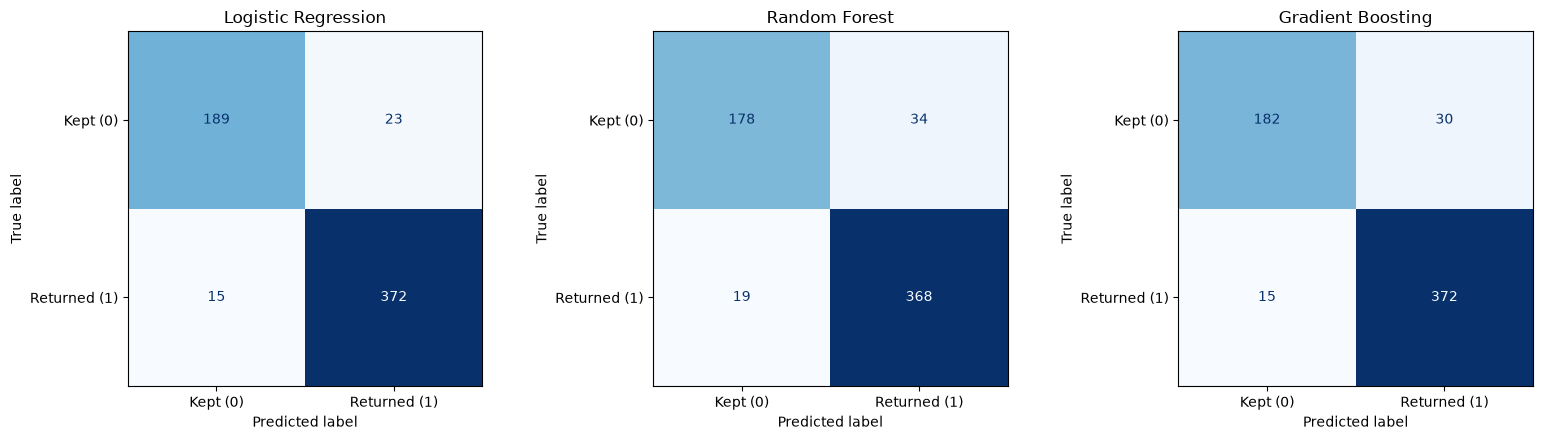

In [46]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, clf_best_models):
    pred = clf_best_models[name].predict(X_test_clf_sel)
    cm = confusion_matrix(y_test_clf, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Kept (0)", "Returned (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

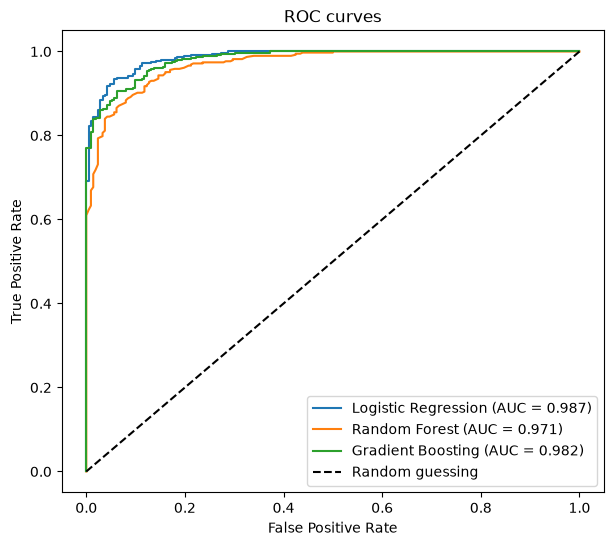

In [47]:
# ROC curves
plt.figure(figsize=(7, 6))
for name, model in clf_best_models.items():
    prob = model.predict_proba(X_test_clf_sel)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_clf, prob)
    plt.plot(fpr, tpr, label=name + " (AUC = " + str(round(roc_auc_score(y_test_clf, prob), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend()
plt.show()

In [48]:
comparison_clf = clf_results[clf_results["Model"] != "Baseline (Majority)"].copy()
comparison_clf["Overfit gap (Acc train - test)"] = (comparison_clf["Accuracy (train)"] - comparison_clf["Accuracy"]).round(4)
comparison_clf["Tuning time (sec)"] = [row[3] for row in clf_tuning_rows]
comparison_clf["CV F1"] = [row[2] for row in clf_tuning_rows]
comparison_clf["Interpretable?"] = ["Yes (coefficients)", "Partly (importances)", "Partly (importances)"]
comparison_clf = comparison_clf.set_index("Model")
display(comparison_clf)

best_clf_name = comparison_clf["F1"].idxmax()
print("Best model by test F1:", best_clf_name)

,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy (train),Overfit gap (Acc train - test),Tuning time (sec),CV F1,Interpretable?
Model,,,,,,,,,,
Logistic Regression,0.9366,0.9418,0.9612,0.9514,0.9866,0.9398,0.0032,0.2,0.9529,Yes (coefficients)
Random Forest,0.9115,0.9154,0.9509,0.9328,0.9706,1.0000,0.0885,8.0,0.9254,Partly (importances)
Gradient Boosting,0.9249,0.9254,0.9612,0.9430,0.9818,0.9699,0.0450,8.1,0.9374,Partly (importances)


Best model by test F1: Logistic Regression


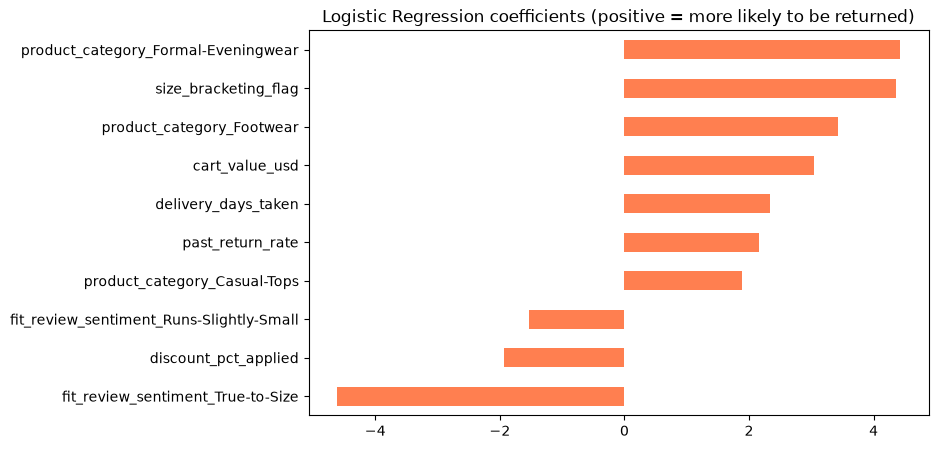

In [49]:
# What drives the return risk in the final model?
best_clf_model = clf_best_models[best_clf_name]

if best_clf_name == "Logistic Regression":
    importance = pd.Series(best_clf_model.named_steps["model"].coef_[0], index=selected_clf_features)
    title = "Logistic Regression coefficients (positive = more likely to be returned)"
else:
    importance = pd.Series(best_clf_model.feature_importances_, index=selected_clf_features)
    title = best_clf_name + " feature importance"

importance.sort_values().plot(kind="barh", figsize=(8, 5), color="coral")
plt.title(title)
plt.show()

In [50]:
import joblib
import numpy as np
import pandas as pd

# Calculate cap limits from training data to avoid NameError
reg_cap_limits = {}
for col in ["creator_followers_k", "engagement_rate_pct", "paid_boost_spend_usd",
            "avg_watch_time_sec", "promo_discount_pct", "caption_word_count",
            "hashtags_used_count"]:
    q1 = X_train_reg[col].quantile(0.25)
    q3 = X_train_reg[col].quantile(0.75)
    iqr = q3 - q1
    reg_cap_limits[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

clf_cap_limits = {}
for col in ["cart_value_usd", "past_return_rate", "delivery_days_taken", "discount_pct_applied"]:
    q1 = X_train_clf[col].quantile(0.25)
    q3 = X_train_clf[col].quantile(0.75)
    iqr = q3 - q1
    clf_cap_limits[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Describe the input boxes of the app (only for columns the final models really use)
def describe_inputs(df, keep_columns):
    info = {}
    for col in keep_columns:
        values = df[col]
        if not pd.api.types.is_numeric_dtype(values):
            options = [str(v) for v in sorted(values.unique())]
            info[col] = {"type": "category", "options": options, "default": str(values.mode()[0])}
        elif values.nunique() <= 2:
            options = [int(v) for v in sorted(values.unique())]
            info[col] = {"type": "category", "options": options, "default": int(values.mode()[0])}
        elif pd.api.types.is_integer_dtype(values):
            info[col] = {"type": "number", "min": int(values.min()), "max": int(values.max()),
                         "default": int(values.median()), "step": 1}
        else:
            span = values.max() - values.min()
            low = float(np.floor(values.min() * 100) / 100)
            high = float(np.ceil(values.max() * 100) / 100)
            info[col] = {"type": "number", "min": low, "max": high,
                         "default": float(round(values.median(), 2)),
                         "step": 0.01 if span <= 10 else 0.1}
    return info

reg_input_columns = [c for c in reg_df.columns if c in keep_original]
clf_input_columns = [c for c in clf_df.columns if c in keep_original_clf]

artifacts = {
    # Regression
    "reg_model": best_reg_model,
    "reg_all_columns": list(X_reg.columns),
    "reg_features": selected_reg_features,
    "reg_cap_limits": reg_cap_limits,
    "reg_inputs": describe_inputs(reg_df, reg_input_columns),
    "reg_mae": float(reg_results.set_index("Model").loc[best_reg_name, "MAE"]),
    # Classification
    "clf_model": best_clf_model,
    "clf_all_columns": list(X_clf.columns),
    "clf_features": selected_clf_features,
    "clf_cap_limits": clf_cap_limits,
    "clf_inputs": describe_inputs(clf_df, clf_input_columns),
}

joblib.dump(artifacts, "deployment_artifacts.joblib")
print("Saved deployment_artifacts.joblib")
print("Regression app inputs:    ", list(artifacts["reg_inputs"].keys()))
print("Classification app inputs:", list(artifacts["clf_inputs"].keys()))

Saved deployment_artifacts.joblib
Regression app inputs:     ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'avg_watch_time_sec', 'promo_discount_pct', 'content_format', 'audience_intent_tier']
Classification app inputs: ['cart_value_usd', 'past_return_rate', 'size_bracketing_flag', 'delivery_days_taken', 'discount_pct_applied', 'product_category', 'fit_review_sentiment']


In [51]:
%%writefile model_utils.py
import os
import joblib
import pandas as pd

ARTIFACT_FILE = os.path.join(os.path.dirname(os.path.abspath(__file__)), "deployment_artifacts.joblib")

# Friendly names shown in the apps
LABELS = {
    "creator_followers_k": "Creator followers (thousands)",
    "engagement_rate_pct": "Engagement rate (%)",
    "paid_boost_spend_usd": "Paid boost spend (USD)",
    "avg_watch_time_sec": "Average watch time (seconds)",
    "promo_discount_pct": "Promo discount offered (%)",
    "content_format": "Content format",
    "audience_intent_tier": "Audience intent tier",
    "cart_value_usd": "Cart value (USD)",
    "past_return_rate": "Customer's past return rate (0 to 1)",
    "size_bracketing_flag": "Size bracketing (1 = several sizes of same item in cart)",
    "delivery_days_taken": "Delivery time (days)",
    "discount_pct_applied": "Discount applied at checkout (%)",
    "product_category": "Product category",
    "fit_review_sentiment": "Fit review sentiment",
}


def label_for(name):
    return LABELS.get(name, name)


def load_artifacts(path=ARTIFACT_FILE):
    return joblib.load(path)


def build_row(raw_inputs, all_columns, cap_limits, selected_features):
    # Start with a row of zeros that has every training column
    row = pd.DataFrame(0.0, index=[0], columns=all_columns)
    for name, value in raw_inputs.items():
        if name in row.columns:
            row[name] = float(value)              # numeric column
        else:
            dummy_name = name + "_" + str(value)  # category -> its one-hot column
            if dummy_name in row.columns:
                row[dummy_name] = 1.0             # (the reference category stays all zeros)
    # Cap extreme values with the limits learned from the training data
    for col, (low, high) in cap_limits.items():
        row[col] = row[col].clip(low, high)
    return row[selected_features]


def predict_revenue(art, inputs):
    row = build_row(inputs, art["reg_all_columns"], art["reg_cap_limits"], art["reg_features"])
    return max(0.0, float(art["reg_model"].predict(row)[0]))


def predict_return_risk(art, inputs):
    row = build_row(inputs, art["clf_all_columns"], art["clf_cap_limits"], art["clf_features"])
    return float(art["clf_model"].predict_proba(row)[0, 1])


def risk_level(probability):
    # Returns a risk label and a suggested business action
    if probability < 0.30:
        return "Low risk", "No action needed. Process the order as normal."
    if probability < 0.70:
        return "Medium risk", "Show size-guide / fit tips at checkout and send a sizing reminder after purchase."
    return "High risk", "Offer a size consultation or exchange-first option, and consider limiting free returns on this order."

Overwriting model_utils.py


In [52]:
from model_utils import load_artifacts, predict_revenue, predict_return_risk, risk_level

art = load_artifacts()

# Regression: compare 100 test campaigns
reg_diffs = []
for i in range(100):
    idx = X_test_reg_sel.index[i]
    raw_inputs = {c: reg_df.loc[idx, c] for c in art["reg_inputs"]}
    app_value = predict_revenue(art, raw_inputs)
    notebook_value = best_reg_model.predict(X_test_reg_sel.iloc[[i]])[0]
    reg_diffs.append(abs(app_value - notebook_value))

# Classification: compare 100 test orders
clf_diffs = []
for i in range(100):
    idx = X_test_clf_sel.index[i]
    raw_inputs = {c: clf_df.loc[idx, c] for c in art["clf_inputs"]}
    app_value = predict_return_risk(art, raw_inputs)
    notebook_value = best_clf_model.predict_proba(X_test_clf_sel.iloc[[i]])[0, 1]
    clf_diffs.append(abs(app_value - notebook_value))

print("Largest difference (revenue, USD):  ", max(reg_diffs))
print("Largest difference (return prob.):  ", max(clf_diffs))

Largest difference (revenue, USD):   0.0
Largest difference (return prob.):   0.0


In [53]:
import pickle

models = {
    "regression": {
        "best_model_name": best_reg_name,
        "best_model": best_reg_model,
        "selected_features": selected_reg_features
    },
    "classification": {
        "best_model_name": best_clf_name,
        "best_model": best_clf_model,
        "selected_features": selected_clf_features
    }
}

with open("model.pkl", "wb") as f:
    pickle.dump(models, f)

In [54]:
with open("model.pkl", "rb") as f:
    models = pickle.load(f)

In [67]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
import sklearn as skl
import streamlit as st

In [68]:
np.__version__, pd.__version__, plt.__version__, sns.__version__,skl.__version__, joblib.__version__, st.__version__

('2.5.4', '3.0.6', '3.11.2', '0.13.2', '1.9.1', '1.6.0', '1.65.0')